# Colombo Land Prices: Explaining the Model with SHAP and LIME

Notebook 02 measured *how well* the final model (the stacked ensemble) predicts. This notebook explains
*why* it predicts what it does, using two methods:

* **SHAP** splits each prediction into a contribution from every feature, so that
  `baseline + sum of contributions = prediction`. Averaged over many listings, it gives a **global** picture
  of what drives prices; for one listing, a **local** explanation.
* **LIME** fits a simple linear model around **one** listing, by perturbing its values and watching how the
  prediction changes. It gives a quick local explanation that can be compared with SHAP's.

Both are applied to the **actual final model** (stacking RF + XGBoost + CatBoost), using model-agnostic
explainers, because a stacked ensemble can't be opened up by tree-specific methods.

In [1]:
import pickle
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split

sys.path.insert(0, ".")  # catboost_wrapper.py, needed to load the pickle
warnings.filterwarnings("ignore")
SEED = 42

with open("land_price_model.pkl", "rb") as f:
    bundle = pickle.load(f)
model, FEATURES = bundle["regressor"], bundle["features"]
print("model:", bundle["regressor_name"])

# Rebuild exactly the same held-out listing and train/test split as notebook 02
df = pd.read_csv("land_prices_clean.csv")
TARGET = "log_price_per_perch"
holdout = df.sample(1, random_state=SEED)
data = df.drop(holdout.index).reset_index(drop=True)
strata = pd.qcut(data[TARGET], 3, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    data[FEATURES], data[TARGET], test_size=0.2, random_state=SEED, stratify=strata)
x_hold = holdout[FEATURES]
print("train", X_train.shape, "| test", X_test.shape, "| held-out:", holdout["Address"].iloc[0])

model: Stacking (RF + XGB + Cat)
train (3419, 33) | test (855, 33) | held-out: dampe


## 1. A numeric view of the data for the explainers

SHAP and LIME perturb feature values numerically, but `Address` is text. Each area is given an integer code,
and a small wrapper turns the codes back into area names before calling the model. The model itself is
unchanged.

The model predicts **log** price per perch, so explanations are on the log scale. A contribution of +0.10
means about +10.5% on the price (e^0.10 = 1.105).

In [2]:
AREAS = sorted(df["Address"].unique())
code_of = {a: i for i, a in enumerate(AREAS)}
ADDR = FEATURES.index("Address")


def to_numeric(X):
    X = X.copy()
    X["Address"] = X["Address"].map(code_of)
    return X.astype(float)


def predict_numeric(A):
    X = pd.DataFrame(A, columns=FEATURES)
    X["Address"] = [AREAS[int(round(c))] for c in X["Address"]]
    return model.predict(X)


# Sanity check: the wrapper gives exactly the same predictions as the model
check = X_test.head(5)
print(np.allclose(predict_numeric(to_numeric(check).values), model.predict(check)))

True


## 2. SHAP: global explanation

`PermutationExplainer` is model-agnostic. It measures each feature's contribution by swapping its value
with values from a **background** sample of 50 training listings. To keep run time reasonable, 120 test
listings are explained. That's enough for a stable global picture.

In [3]:
background = to_numeric(X_train.sample(50, random_state=SEED))
sample = X_test.sample(120, random_state=SEED)
masker = shap.maskers.Independent(background.values, max_samples=50)
explainer = shap.PermutationExplainer(predict_numeric, masker, feature_names=FEATURES, seed=SEED)

sv = explainer(to_numeric(sample).values, silent=True)
print("baseline (average log price of the background):", round(float(sv.base_values[0]), 3))

baseline (average log price of the background): 13.898


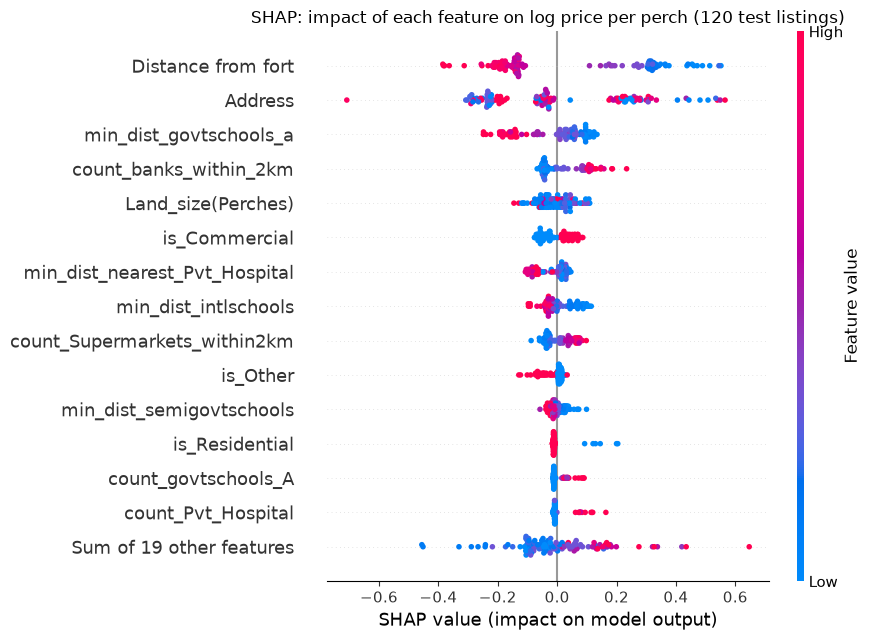

In [4]:
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP: impact of each feature on log price per perch (120 test listings)")
plt.gcf().set_size_inches(9, 6.5)
plt.tight_layout()
plt.savefig("figures/fig7_shap_beeswarm.png", dpi=110, bbox_inches="tight")
plt.show()

**How to read it.** Each dot is one listing. Its position shows how much that feature pushed the
prediction up (right) or down (left). Its colour shows the feature's value (red = high, blue = low).
For example, red dots on the left for `Distance from fort` would mean that a long distance from the city
lowers the price.

## 3. SHAP: grouped view (location vs. size vs. land type)

Notebook 03 showed that every location feature is **constant within an area**. The 27 distance and count
features and `Address` therefore describe the same thing, and SHAP has to split the credit between them
somewhat arbitrarily. Adding their contributions together gives a fairer picture.

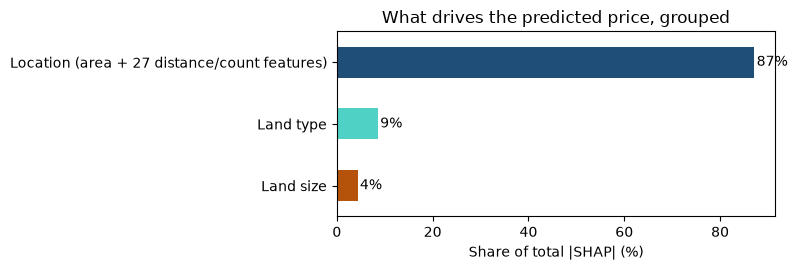

Land size                                        4.3
Land type                                        8.6
Location (area + 27 distance/count features)    87.1
dtype: float64

In [5]:
contrib = pd.DataFrame(np.abs(sv.values), columns=FEATURES)
groups = {
    "Location (area + 27 distance/count features)": [c for c in FEATURES if c == "Address"
                                                      or c.startswith(("min_dist", "count", "Distance"))],
    "Land size": ["Land_size(Perches)"],
    "Land type": [c for c in FEATURES if c.startswith("is_")],
}
grouped = pd.Series({g: contrib[cols].sum(axis=1).mean() for g, cols in groups.items()})
share = (grouped / grouped.sum()).sort_values()

ax = share.mul(100).plot.barh(figsize=(8, 2.8), color=["#B45309", "#4fd1c5", "#1F4E79"])
ax.set_xlabel("Share of total |SHAP| (%)")
ax.set_title("What drives the predicted price, grouped")
for i, v in enumerate(share.mul(100)):
    ax.text(v + 0.5, i, f"{v:.0f}%", va="center")
plt.tight_layout()
plt.savefig("figures/fig8_shap_grouped.png", dpi=110, bbox_inches="tight")
plt.show()
share.mul(100).round(1)

## 4. SHAP: local explanation of the held-out listing

The listing kept aside in notebook 02 (Dampe, 9.7 perches, actual Rs 300,000 per perch, predicted
Rs 332,620). The waterfall starts at the average prediction and adds each feature's contribution until it
reaches this listing's prediction.

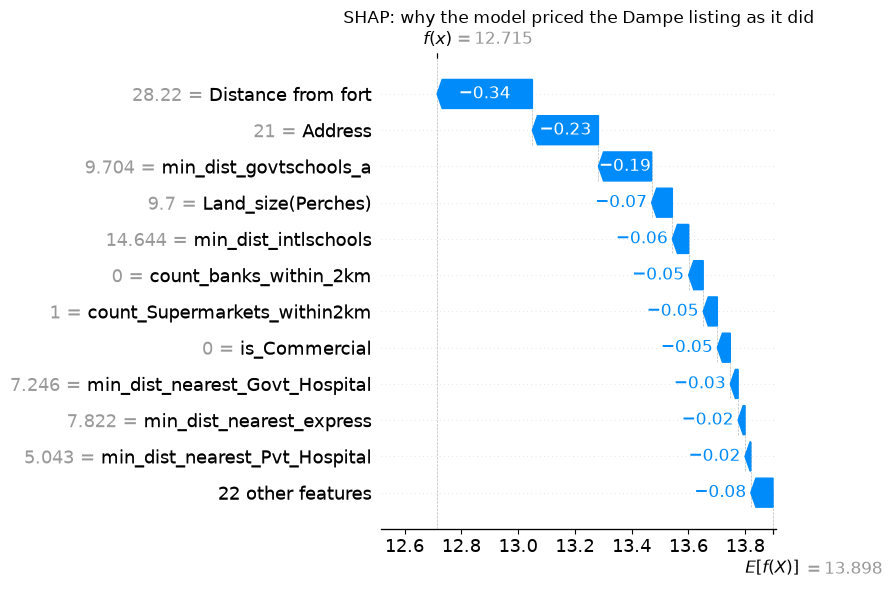

baseline 13.898 + contributions -1.183 = 12.715  ->  Rs 332,620 per perch


Distance from fort       -0.336
Address                  -0.233
min_dist_govtschools_a   -0.187
Land_size(Perches)       -0.073
min_dist_intlschools     -0.057
count_banks_within_2km   -0.051
dtype: float64

In [6]:
sv_hold = explainer(to_numeric(x_hold).values, silent=True)
shap.plots.waterfall(sv_hold[0], max_display=12, show=False)
plt.title("SHAP: why the model priced the Dampe listing as it did")
plt.gcf().set_size_inches(9, 6)
plt.tight_layout()
plt.savefig("figures/fig9_shap_waterfall.png", dpi=110, bbox_inches="tight")
plt.show()

pred_log = float(sv_hold.base_values[0] + sv_hold.values[0].sum())
print(f"baseline {sv_hold.base_values[0]:.3f} + contributions {sv_hold.values[0].sum():+.3f} = {pred_log:.3f}"
      f"  ->  Rs {np.expm1(pred_log):,.0f} per perch")
hold_shap = pd.Series(sv_hold.values[0], index=FEATURES)
hold_shap.reindex(hold_shap.abs().sort_values(ascending=False).index).head(6).round(3)

## 5. LIME: local explanation of the same listing

LIME creates 5,000 perturbed copies of the listing, asks the model to price each one, and fits a weighted
linear model to those answers. `Address` is declared categorical, so LIME swaps whole areas rather than
treating the area code as a number.

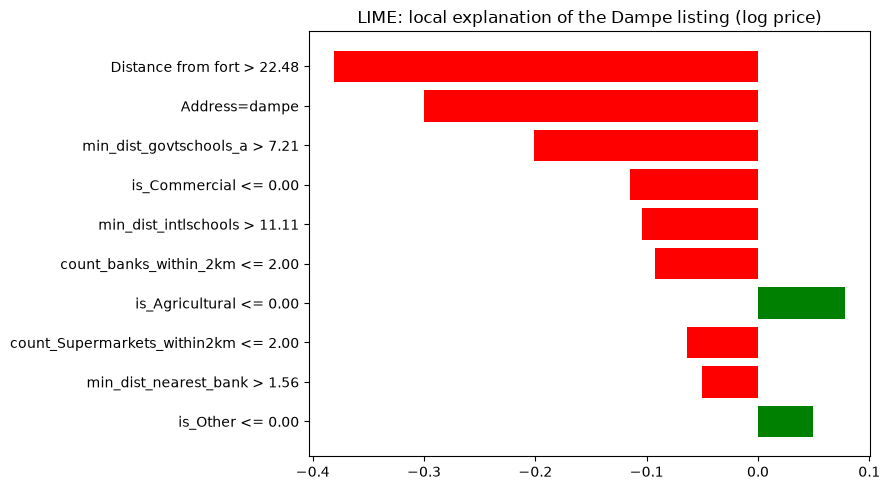

LIME local model R²: 0.289


,condition,effect on log price
0,Distance from fort > 22.48,-0.380
1,Address=dampe,-0.300
2,min_dist_govtschools_a > 7.21,-0.201
3,is_Commercial <= 0.00,-0.115
4,min_dist_intlschools > 11.11,-0.104
5,count_banks_within_2km <= 2.00,-0.092
6,is_Agricultural <= 0.00,0.078
7,count_Supermarkets_within2km <= 2.00,-0.063
8,min_dist_nearest_bank > 1.56,-0.050
9,is_Other <= 0.00,0.049


In [7]:
X_train_num = to_numeric(X_train)
lime_exp = LimeTabularExplainer(
    X_train_num.values, feature_names=FEATURES, mode="regression",
    categorical_features=[ADDR], categorical_names={ADDR: AREAS},
    discretize_continuous=True, random_state=SEED)

exp = lime_exp.explain_instance(to_numeric(x_hold).values[0], predict_numeric, num_features=10,
                                num_samples=5000)
fig = exp.as_pyplot_figure()
fig.set_size_inches(9, 5)
plt.title("LIME: local explanation of the Dampe listing (log price)")
plt.tight_layout()
plt.savefig("figures/fig10_lime.png", dpi=110, bbox_inches="tight")
plt.show()
print(f"LIME local model R\u00b2: {exp.score:.3f}")
pd.DataFrame(exp.as_list(), columns=["condition", "effect on log price"]).round(3)

## 6. Do SHAP and LIME agree?

Both methods are compared on the held-out listing: which features they rank as most influential, and in
which direction.

In [8]:
def base_feature(condition):
    # LIME conditions look like "Distance from fort > 22.48" or "Address=dampe"; map back to the column
    for f in sorted(FEATURES, key=len, reverse=True):
        if f in condition:
            return f
    return condition

lime_s = pd.Series({base_feature(c): w for c, w in exp.as_list()})
top = hold_shap.abs().sort_values(ascending=False).head(8).index
comparison = pd.DataFrame({
    "SHAP contribution": hold_shap[top].round(3),
    "LIME weight": lime_s.reindex(top).round(3),
})
same = np.sign(comparison["SHAP contribution"]) == np.sign(comparison["LIME weight"])
comparison["same direction"] = np.where(comparison["LIME weight"].isna(), "not in LIME's top 10",
                                        np.where(same, "yes", "no"))
comparison

,SHAP contribution,LIME weight,same direction
Distance from fort,-0.336,-0.380,yes
Address,-0.233,-0.300,yes
min_dist_govtschools_a,-0.187,-0.201,yes
Land_size(Perches),-0.073,NaN,not in LIME's top 10
min_dist_intlschools,-0.057,-0.104,yes
count_banks_within_2km,-0.051,-0.092,yes
count_Supermarkets_within2km,-0.050,-0.063,yes
is_Commercial,-0.046,-0.115,yes


## 7. CatBoost: what the "new algorithm" learned

CatBoost wasn't covered in the lectures and is the project's main new algorithm (report Section 4.3). It's
one of the three members of the final stack. Because it's a tree model, its SHAP values can be computed
**exactly**, using CatBoost's own built-in SHAP calculation instead of sampling. They are computed for the
same 120 test listings as above.

exact additivity: True


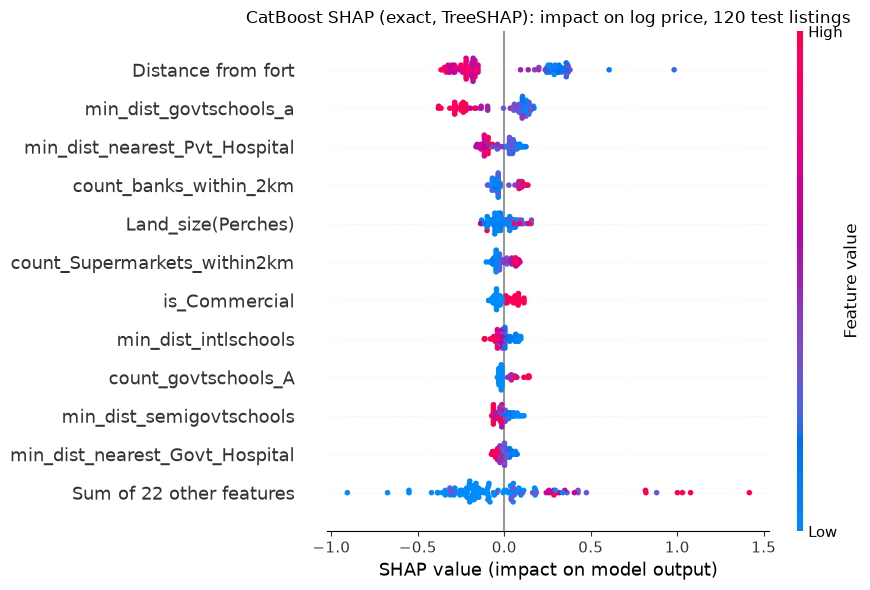

In [9]:
from catboost import Pool

cat_member = model.named_estimators_["cat"].model_       # fitted CatBoostRegressor inside the wrapper
pool = Pool(sample, cat_features=["Address"])
raw = cat_member.get_feature_importance(data=pool, type="ShapValues")   # last column = expected value
cat_sv = shap.Explanation(values=raw[:, :-1], base_values=raw[:, -1], data=to_numeric(sample).values,
                          feature_names=FEATURES)

# exact: contributions + baseline reproduce CatBoost's own predictions
print("exact additivity:", np.allclose(raw.sum(axis=1), cat_member.predict(sample)))

shap.plots.beeswarm(cat_sv, max_display=12, show=False)
plt.title("CatBoost SHAP (exact, TreeSHAP): impact on log price, 120 test listings")
plt.gcf().set_size_inches(9, 6)
plt.tight_layout()
plt.savefig("figures/fig11_catboost_shap.png", dpi=110, bbox_inches="tight")
plt.show()

In [10]:
cat_abs = pd.DataFrame(np.abs(cat_sv.values), columns=FEATURES)
cat_grouped = pd.Series({g: cat_abs[cols].sum(axis=1).mean() for g, cols in groups.items()})
compare = pd.DataFrame({
    "CatBoost (exact SHAP)": (cat_grouped / cat_grouped.sum() * 100).round(1),
    "Final stack (permutation SHAP)": (grouped / grouped.sum() * 100).round(1),
})
print("share of total |SHAP| (%)")
display(compare)

top_cat = cat_abs.mean().sort_values(ascending=False).head(6)
top_stack = contrib.mean().sort_values(ascending=False).head(6)
print("top features - CatBoost:", list(top_cat.index))
print("top features - stack:   ", list(top_stack.index))

share of total |SHAP| (%)


,CatBoost (exact SHAP),Final stack (permutation SHAP)
Location (area + 27 distance/count features),86.5,87.1
Land size,4.6,4.3
Land type,9.0,8.6


top features - CatBoost: ['Distance from fort', 'min_dist_govtschools_a', 'min_dist_nearest_Pvt_Hospital', 'count_banks_within_2km', 'Land_size(Perches)', 'count_Supermarkets_within2km']
top features - stack:    ['Distance from fort', 'Address', 'min_dist_govtschools_a', 'count_banks_within_2km', 'Land_size(Perches)', 'is_Commercial']


## 8. Partial dependence: how price changes with one feature

A **partial dependence plot (PDP)** shows the model's average prediction as one feature is varied and everything
else is kept as it is in the data. It's computed here directly: for each grid value, set the feature to that value
for 300 test listings, predict, and average.

Caveat (as for SHAP and LIME): location features never vary within an area in the real data, so varying one
of them on its own shows the model's response to a combination that doesn't occur. Read these as the *direction*
the model has learned, not as exact effects.

Distance from fort: 6.54 -> 36.09 changes average prediction Rs 2,166,519 -> Rs 986,571


Land_size(Perches): 6.00 -> 81.28 changes average prediction Rs 1,725,960 -> Rs 1,857,431


count_banks_within_2km: 0.00 -> 43.00 changes average prediction Rs 1,538,841 -> Rs 1,881,640


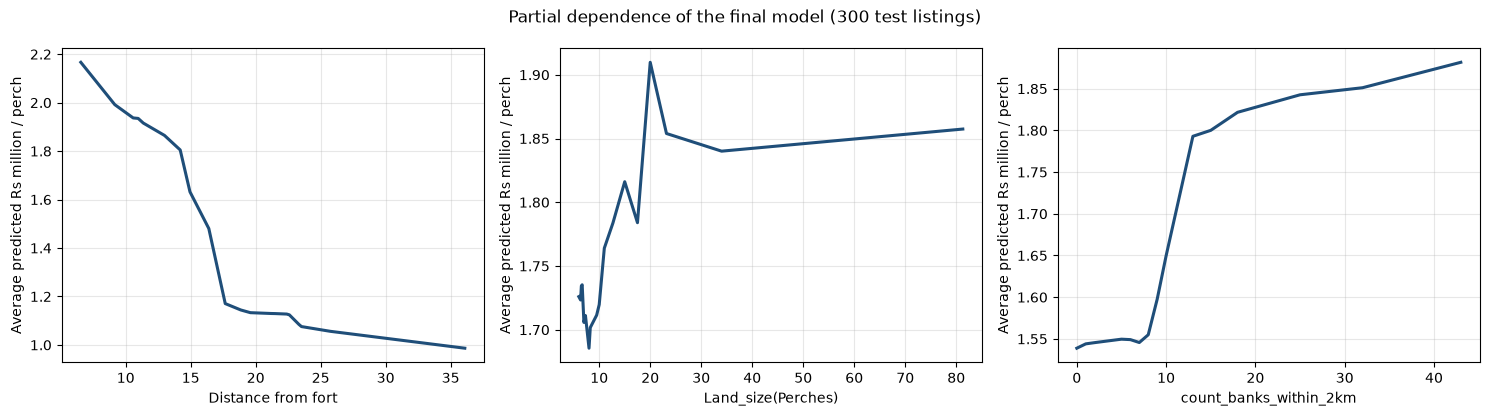

In [11]:
pdp_sample = X_test.sample(300, random_state=SEED)
PDP_FEATURES = ["Distance from fort", "Land_size(Perches)", "count_banks_within_2km"]


def partial_dependence(feature, n_grid=20):
    grid = np.unique(np.quantile(X_train[feature], np.linspace(0.02, 0.98, n_grid)))
    avg = []
    for v in grid:
        X_mod = pdp_sample.copy()
        X_mod[feature] = v
        avg.append(np.expm1(model.predict(X_mod)).mean())
    return grid, np.array(avg)


fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, f in zip(axes, PDP_FEATURES):
    g, a = partial_dependence(f)
    ax.plot(g, a / 1e6, color="#1F4E79", lw=2.2)
    ax.set_xlabel(f)
    ax.set_ylabel("Average predicted Rs million / perch")
    ax.grid(alpha=0.3)
    print(f"{f}: {g[0]:.2f} -> {g[-1]:.2f} changes average prediction Rs {a[0]:,.0f} -> Rs {a[-1]:,.0f}")
fig.suptitle("Partial dependence of the final model (300 test listings)")
plt.tight_layout()
plt.savefig("figures/fig12_pdp.png", dpi=110, bbox_inches="tight")
plt.show()

## 9. Summary

*Written up in the report, Section 6.4, using the numbers above.*

**Caveat for both methods.** SHAP's background sampling and LIME's perturbations change one feature at a
time, independently of the others. Here, the location features always move together within an area, so some
perturbed listings combine one area's name with another area's distances, which never happens in the real
data. That's why the **grouped** SHAP view (Section 3) is the most reliable reading, and why the individual
location features should be read as a group rather than one by one.